In [1]:
# ── KAGGLE SETUP (only runs on Kaggle, no-op everywhere else) ───────────────
import os, sys
from pathlib import Path

if os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or Path("/kaggle/input").exists():
    import subprocess
    REPO_URL = "https://github.com/ltruonghai257/fake-new-detection.git"
    CLONE_DIR = Path("/kaggle/working/fake-news-detection")
    if not CLONE_DIR.exists():
        subprocess.run(["git", "clone", REPO_URL, str(CLONE_DIR)], check=True)
        print(f"Cloned → {CLONE_DIR}")
    # Install project deps first (requirements.txt resolves torch>=2.12 → 2.14 nightly)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r",
         str(CLONE_DIR / "requirements.txt")], check=True,
    )
    # Override torch AFTER requirements.txt so it is not overwritten.
    # --no-deps prevents pip re-resolving transitive deps and pulling nightly back.
    # torch 2.4.1+cu121 bundles its own NCCL → fixes "undefined symbol: ncclCommResume".
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "torch==2.4.1", "torchvision==0.19.1",
        "--index-url", "https://download.pytorch.org/whl/cu121",
        "--force-reinstall", "--no-deps",
    ], check=True)
    print(f"PyTorch pinned: torch==2.4.1+cu121")
    def _find_hdf5_root():
        for d in Path("/kaggle/input").rglob("processed_data/hdf5"):
            if d.is_dir(): return d.parent.parent
        return None
    hdf5_root = _find_hdf5_root()
    if hdf5_root is None:
        raise RuntimeError("processed_data/hdf5/ not found under /kaggle/input/")
    (CLONE_DIR / ".env.kaggle").write_text(f"DATA_ROOT={hdf5_root}\nPLATFORM=kaggle\n")
    print(f"DATA_ROOT={hdf5_root}")
else:
    print("Not Kaggle — setup skipped.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchaudio 2.10.0+cu128 requires torch==2.10.0, but you have torch 2.14.0 which is incompatible.


PyTorch pinned: torch==2.4.1+cu121
DATA_ROOT=/kaggle/input/datasets/trnghil/coolant-train-new


In [2]:
# ── Environment + path setup ────────────────────────────────────────────────
import os, sys
from pathlib import Path

def _detect_platform():
    if os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or Path("/kaggle/input").exists():
        return "kaggle"
    try:
        import google.colab; return "colab"
    except ImportError: pass
    if Path("/workspace").exists(): return "vastai"
    if sys.platform == "darwin": return "mac"
    return "windows"

PLATFORM = _detect_platform()

try:
    _nb_path = Path(__file__).resolve()
except NameError:
    _nb_path = Path.cwd()

if PLATFORM == "colab":
    from google.colab import drive; drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/Thesis_Final/fake-news-detection")
elif PLATFORM == "kaggle":
    PROJECT_ROOT = Path(os.environ.get("KAGGLE_PROJECT_ROOT", "/kaggle/working/fake-news-detection"))
else:
    PROJECT_ROOT = _nb_path.parents[1] if _nb_path.name.endswith(".ipynb") else Path.cwd().parents[1]

sys.path.insert(0, str(PROJECT_ROOT))

from dotenv import load_dotenv
_env_file = PROJECT_ROOT / f".env.{PLATFORM}"
if not _env_file.exists(): _env_file = PROJECT_ROOT / ".env"
load_dotenv(_env_file, override=True)

from src.utils.env_utils import get_data_root
DATA_ROOT = get_data_root()
print(f"Platform : {PLATFORM}")
print(f"DATA_ROOT: {DATA_ROOT}  (exists={DATA_ROOT.exists()})")

Platform : kaggle
DATA_ROOT: /kaggle/input/datasets/trnghil/coolant-train-new  (exists=True)


# COOLANT v2 — Paper-Faithful Training (GatedMLP)

Paper: *Cross-modal Contrastive Learning for Multimodal Fake News Detection* (ACM MM '23)

**Loss schedule per §3.2 (paper gốc, `use_itc=True`):**
```
Task 1a — Consistency:  L_ITM = CosineEmbeddingLoss(e_s_t, e_s_v, ±1)   §3.2.1
Task 1b — Contrastive:  L_ITC = symmetric InfoNCE(m_t, m_v)               §3.2.2
Task 1c — Soft distill: L_SEM = soft-CE(S_ITM → P_ITC)                   §3.2.4
           Combined:     L_CL  = L_ITC + λ·L_SEM                          Eq. 7
Task 2  — Detection:    L_DET = L_CE + 0.5·L_KL                          §3.4.3
```

**Notation (paper → code):**
- `e_s_t`, `e_s_v` — shared embeddings from `SimilarityModule` (→ L_ITM, soft targets)
- `m_t`,   `m_v`   — aligned representations from `CLIPModule`  (→ L_ITC, CrossModule)

**Modifications vs paper:** only GatedMLP (SwiGLU) replaces standard MLPs.

**`use_itc=False`** = ablation mode (only L_ITM + L_DET, no CLIPModule).

In [3]:
# ── CONFIG — edit this cell only ────────────────────────────────────────────
CONFIG = {
    "paths": {
        "train_hdf5": DATA_ROOT / "processed_data" / "hdf5" / "coolant_train.h5",
        "dev_hdf5":   DATA_ROOT / "processed_data" / "hdf5" / "coolant_dev.h5",
        "test_hdf5":  DATA_ROOT / "processed_data" / "hdf5" / "coolant_test.h5",
        "checkpoint_root": DATA_ROOT / "training" / "checkpoints_coolant_v2",
    },
    "model": {
        # Feature dimensions (match HDF5 preprocessing output)
        "text_input_dim":  768,   # PhoBERT embed dim
        "image_input_dim": 2048,  # ResNet50 feature dim
        # COOLANT_Official architecture
        "shared_dim":  128,
        "sim_dim":      64,
        "feature_dim":  96,   # 64 + 16 + 16
        "h_dim":        64,
        # Paper §3.2: use_itc=True = full paper (L_ITM + L_ITC + L_SEM + L_DET)
        # use_itc=False = ablation (L_ITM + L_DET only, no CLIPModule)
        "use_itc":        True,
        "clip_embed_dim": 64,
        "sem_weight":      1.0,   # λ in L_CL = L_ITC + λ·L_SEM  (Eq. 7)
        "itm_weight":      0.5,   # weight of L_ITM relative to L_CL
    },
    "training": {
        "batch_size":              64,
        "max_epochs":             80,
        "negative_shift":           3,
        "min_batch_for_negatives":  4,
        "grad_clip":              1.0,
        "grad_accumulation_steps":  2,    # ↓ from 4 — reduces peak memory (was causing CUDA OOM warnings)
        "warmup_epochs":            10,    # ↑ from 3 — slower ramp-up reduces early instability
        "lr":                    1e-4,    # ↓ from 1e-3 — reduces class-collapse oscillation
        "weight_decay":          1e-2,    # ↑ from 1e-5 — standard AdamW L2 regularization
        "seed":                    42,
        "detection_weight":       1.0,
        # ── Stability fixes ──────────────────────────────────────────────
        # Root cause of the oscillating val_f1 (e.g. 0.538 → 0.336 → 0.333 → 0.626):
        # DetectionModule consumes m_t/m_v from CLIPModule/SimilarityModule, which
        # are simultaneously retrained by a *different* optimizer every step
        # (moving-target problem) + noisy BatchNorm stats at small batch size.
        "detection_warmup_epochs": 5,   # freeze DetectionModule for first N epochs;
                                         # let SimilarityModule/CLIPModule stabilize first
                                         # (2-stage warmup, removes early moving-target noise)
        "val_ema_decay":          0.6,   # EMA smoothing of val_macro_f1 used for checkpoint
                                         # selection, so "best" isn't a single lucky/noisy epoch
        "early_stopping_patience": 25,   # stop if EMA(val_macro_f1) doesn't improve for N epochs
    },
    "checkpointing": {
        "selection_metric": "val_macro_f1",
        "checkpoint_every":  5,
    },
    "safety": {
        "smoke_test":            False,
        "smoke_batches":             2,
        "resume_from_checkpoint": None,
    },
}

# Kaggle: redirect writable outputs
if os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or Path("/kaggle/input").exists():
    CONFIG["paths"]["checkpoint_root"] = Path("/kaggle/working/checkpoints_coolant_v2")

CONFIG["paths"]["checkpoint_root"].mkdir(parents=True, exist_ok=True)
print("CONFIG loaded.")

CONFIG loaded.


In [4]:
# ── Imports ──────────────────────────────────────────────────────────────────
import gc, json, random, hashlib
from copy import deepcopy
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import h5py
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report

# Project modules
from src.models.coolant_official import COOLANT_Official
from src.preprocessing.coolant.pair_dataset import create_coolant_dataloaders
from src.preprocessing.coolant.training_utils import make_coolant_pairs, make_detection_batch

print(f"PyTorch: {torch.__version__}")

PyTorch: 2.4.1+cu121


In [5]:
# ── Device, seed, dataloaders ────────────────────────────────────────────────
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps"  if torch.backends.mps.is_available() else "cpu")
seed_everything(CONFIG["training"]["seed"])
print(f"Device: {DEVICE}")

loaders, datasets = create_coolant_dataloaders(
    str(CONFIG["paths"]["train_hdf5"]),
    str(CONFIG["paths"]["dev_hdf5"]),
    str(CONFIG["paths"]["test_hdf5"]),
    batch_size=CONFIG["training"]["batch_size"],
)

if CONFIG["safety"]["smoke_test"]:
    from itertools import islice
    class _SmokeLoader:
        def __init__(self, l, n): self._l, self._n = l, n
        def __iter__(self): return islice(self._l, self._n)
        def __len__(self): return min(self._n, len(self._l))
    loaders = {k: _SmokeLoader(v, CONFIG["safety"]["smoke_batches"]) for k, v in loaders.items()}
    print(f"SMOKE TEST: {CONFIG['safety']['smoke_batches']} batches/split")

# Verify shapes
_cap, _img, _ = next(iter(loaders["train"]))
print(f"caption: {tuple(_cap.shape)}  (B, embed=768, seq=128)")
print(f"image:   {tuple(_img.shape)}  (B, 2048)")

Device: cuda
CoolantPairDataset: 7664 pairs from coolant_train.h5
CoolantPairDataset: 1025 pairs from coolant_dev.h5
CoolantPairDataset: 950 pairs from coolant_test.h5

COOLANT DataLoaders created:
  Train: 120 batches (7664 pairs)
  Dev:   17 batches (1025 pairs)
  Test:  15 batches (950 pairs)
caption: (64, 768, 128)  (B, embed=768, seq=128)
image:   (64, 2048)  (B, 2048)


In [6]:
# ── Build COOLANT_Official ───────────────────────────────────────────────────
model_cfg = {
    "text_input_dim":  CONFIG["model"]["text_input_dim"],
    "image_input_dim": CONFIG["model"]["image_input_dim"],
    "text_seq_len":    CONFIG["model"].get("text_seq_len", 128),
    "shared_dim":      CONFIG["model"]["shared_dim"],
    "sim_dim":         CONFIG["model"]["sim_dim"],
    "feature_dim":     CONFIG["model"]["feature_dim"],
    "h_dim":           CONFIG["model"]["h_dim"],
    "use_itc":         CONFIG["model"]["use_itc"],
    "clip_embed_dim":  CONFIG["model"]["clip_embed_dim"],
    "sem_weight":      CONFIG["model"]["sem_weight"],  # λ for L_SEM (§3.2.4)
    "itm_weight":      CONFIG["model"]["itm_weight"],
}
model = COOLANT_Official(model_cfg).to(DEVICE)

total_p = sum(p.numel() for p in model.parameters())
sim_p   = sum(p.numel() for p in model.similarity_module.parameters())
det_p   = sum(p.numel() for p in model.detection_module.parameters())
print(f"Parameters total:                    {total_p:,}")
print(f"  SimilarityModule (L_ITM, §3.2.1):  {sim_p:,}")
if model.use_itc:
    itc_p = sum(p.numel() for p in model.clip_module.parameters())
    print(f"  CLIPModule       (L_ITC, §3.2.2):  {itc_p:,}")
print(f"  DetectionModule  (L_DET, §3.4):    {det_p:,}")
print(f"\nuse_itc = {model.use_itc}  →  {'Full paper (L_ITM+L_ITC+L_SEM+L_DET)' if model.use_itc else 'Ablation (L_ITM+L_DET)'}")

Parameters total:                    6,456,460
  SimilarityModule (L_ITM, §3.2.1):  1,043,136
  CLIPModule       (L_ITC, §3.2.2):  1,474,561
  DetectionModule  (L_DET, §3.4):    3,938,763

use_itc = True  →  Full paper (L_ITM+L_ITC+L_SEM+L_DET)


In [7]:
# ── Losses, optimizers, LR schedulers ───────────────────────────────────────
# Loss functions (built-in, only L_CE/L_KL; L_ITM/L_ITC/L_SEM via model methods)
loss_ce = nn.CrossEntropyLoss(label_smoothing=0.05)   # part of L_DET
loss_kl = nn.KLDivLoss(reduction="batchmean")          # part of L_DET

def _make_optim(params, lr=None):
    _lr = lr or CONFIG["training"]["lr"]
    _wd = CONFIG["training"]["weight_decay"]
    return torch.optim.AdamW(params, lr=_lr, betas=(0.9, 0.999),
                             eps=1e-8, weight_decay=_wd)

# One optimizer per module (paper approach)
OPTIMIZERS = {
    "similarity": _make_optim(model.similarity_module.parameters()),  # Task 1a L_ITM
    "detection":  _make_optim(model.detection_module.parameters()),   # Task 2  L_DET
}
if model.use_itc:
    # CLIPModule trained with L_CL = L_ITC + λ·L_SEM
    OPTIMIZERS["itc"] = _make_optim(model.clip_module.parameters())

def _make_scheduler(opt):
    wu = CONFIG["training"]["warmup_epochs"]
    T  = CONFIG["training"]["max_epochs"]
    def _lr(ep):
        if ep < wu: return ep / max(1, wu)
        p = (ep - wu) / max(1, T - wu)
        return max(0.0, 0.5 * (1 + torch.cos(torch.tensor(3.14159265 * p)).item()))
    return torch.optim.lr_scheduler.LambdaLR(opt, _lr)

SCHEDULERS = {k: _make_scheduler(opt) for k, opt in OPTIMIZERS.items()}
print(f"Optimizers: {list(OPTIMIZERS.keys())}  (AdamW)")
print(f"Scheduler: warmup={CONFIG['training']['warmup_epochs']}, cosine to epoch {CONFIG['training']['max_epochs']}")

Optimizers: ['similarity', 'detection', 'itc']  (AdamW)
Scheduler: warmup=10, cosine to epoch 80


In [8]:
# ── One-batch sanity check ───────────────────────────────────────────────────
model.train()
_cap, _img, _ = next(iter(loaders["train"]))
_cap, _img = _cap.to(DEVICE), _img.to(DEVICE)

# Task 1a: L_ITM — consistency (§3.2.1)
_cap_a, _img_m, _img_u = make_coolant_pairs(_cap, _img, shift=CONFIG["training"]["negative_shift"])
_e_s_t_m, _e_s_v_m, _ = model.similarity_module(_cap_a, _img_m)
_e_s_t_u, _e_s_v_u, _ = model.similarity_module(_cap_a, _img_u)
_lbl_m = torch.ones(_cap_a.size(0), device=DEVICE)
_lbl_u = -torch.ones(_cap_a.size(0), device=DEVICE)
_e_s_t_all = torch.cat([_e_s_t_m, _e_s_t_u], dim=0)
_e_s_v_all = torch.cat([_e_s_v_m, _e_s_v_u], dim=0)
_lbl_all   = torch.cat([_lbl_m, _lbl_u], dim=0)
_l_itm = model.compute_loss_itm(_e_s_t_all, _e_s_v_all, _lbl_all)

# Task 1b+c: L_ITC + L_SEM (§3.2.2 + §3.2.4)
_l_itc = _l_sem = torch.tensor(0.0)
if model.use_itc:
    _m_t, _m_v = model.clip_module(_cap, _img)
    _e_s_t_full, _e_s_v_full, _ = model.similarity_module(_cap, _img)
    _l_itc = model.compute_loss_itc(_m_t, _m_v)
    _l_sem = model.compute_loss_sem(_m_t, _m_v, _e_s_t_full, _e_s_v_full)

# Task 2: L_DET (§3.4.3) — same path as training: detached features + detection_module
_dc, _di, _dl = make_detection_batch(_cap, _img, shift=CONFIG["training"]["negative_shift"])
_dc, _di, _dl = _dc.to(DEVICE), _di.to(DEVICE), _dl.to(DEVICE)
with torch.no_grad():
    _m_t_d, _m_v_d = (model.clip_module(_dc, _di) if model.use_itc
                      else model.similarity_module(_dc, _di)[:2])
_det_logits, _det_att, _det_amb = model.detection_module(_dc, _di, _m_t_d, _m_v_d)
_l_ce  = loss_ce(_det_logits, _dl)
_l_kl  = loss_kl(F.log_softmax(_det_att.clamp(-10,10), dim=1),
                  F.softmax(_det_amb.clamp(-10,10), dim=1))
_l_det = _l_ce + 0.5 * _l_kl

print(f"L_ITM  = {_l_itm.item():.4f}  {'OK' if torch.isfinite(_l_itm) else 'NaN!'}")
print(f"L_ITC  = {_l_itc.item():.4f}  {'OK' if torch.isfinite(_l_itc) else 'NaN!'}")
print(f"L_SEM  = {_l_sem.item():.4f}  {'OK' if torch.isfinite(_l_sem) else 'NaN!'}")
print(f"L_CE   = {_l_ce.item():.4f}   L_KL = {_l_kl.item():.4f}")
print(f"L_DET  = {_l_det.item():.4f}  {'OK' if torch.isfinite(_l_det) else 'NaN!'}")
print("Sanity check passed.")

L_ITM  = 0.5055  OK
L_ITC  = 4.1807  OK
L_SEM  = 4.1682  OK
L_CE   = 0.6919   L_KL = 0.0020
L_DET  = 0.6929  OK
Sanity check passed.


In [9]:
# ── Run directory + checkpoint helpers ──────────────────────────────────────
import shutil

timestamp  = datetime.now().strftime("%Y%m%d_%H%M%S")
run_name   = f"coolant_v2_{timestamp}"
run_dir    = CONFIG["paths"]["checkpoint_root"] / run_name
run_dir.mkdir(parents=True, exist_ok=True)
print(f"Run dir: {run_dir}")

def save_checkpoint(path, model, epoch, history, metrics, is_best=False):
    ckpt = {
        "model_state_dict":          model.state_dict(),
        "similarity_module_state":   model.similarity_module.state_dict(),
        "detection_module_state":    model.detection_module.state_dict(),
        "epoch": epoch,
        "metrics": metrics,
        "training_history": history,
        "use_itc": model.use_itc,
    }
    if model.use_itc:
        ckpt["clip_module_state"] = model.clip_module.state_dict()
    torch.save(ckpt, path)

def load_checkpoint(path, model):
    ckpt = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    print(f"Loaded checkpoint from epoch {ckpt['epoch']}: {path}")
    return ckpt

if CONFIG["safety"]["resume_from_checkpoint"]:
    _ckpt = load_checkpoint(CONFIG["safety"]["resume_from_checkpoint"], model)
    start_epoch = _ckpt["epoch"] + 1
else:
    start_epoch = 0

print("Checkpoint helpers ready. start_epoch =", start_epoch)

# ── Kaggle auto-upload best model (an toàn khi treo máy) ────────────────────
# SETUP: Add-ons → Secrets → KAGGLE_USERNAME + KAGGLE_KEY
IS_KAGGLE = os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or Path("/kaggle/input").exists()
_KAGGLE_API = None
_KAGGLE_UPLOAD_OK = False

if IS_KAGGLE:
    try:
        from kaggle_secrets import UserSecretsClient
        _sec = UserSecretsClient()
        os.environ["KAGGLE_USERNAME"] = _sec.get_secret("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"]      = _sec.get_secret("KAGGLE_KEY")
        from kaggle.api.kaggle_api_extended import KaggleApi
        _KAGGLE_API = KaggleApi(); _KAGGLE_API.authenticate()
        _KAGGLE_UPLOAD_OK = True
        print(f"Kaggle API authenticated as {os.environ['KAGGLE_USERNAME']}")
    except Exception as e:
        print(f"⚠ Kaggle secrets/API chưa setup ({e}) — best model chỉ lưu ở Output tab.")

_BEST_DS_SLUG = "coolant-v2-best"   # dataset chứa best model mới nhất

def kaggle_upload_best(ckpt_path, epoch, f1):
    """Upload best checkpoint lên private Kaggle Dataset mỗi khi best mới.
    Dataset = 1 version/best → treo máy hay crash cũng không mất."""
    if not _KAGGLE_UPLOAD_OK:
        return
    try:
        staging = Path("/kaggle/working/_ds_best")
        staging.mkdir(exist_ok=True)
        for old in staging.glob("*.pth"): old.unlink()
        shutil.copy2(ckpt_path, staging / "best_macro_f1.pth")
        (staging / "best_info.json").write_text(json.dumps({
            "run": run_name, "epoch": int(epoch), "val_macro_f1": float(f1),
            "use_itc": bool(model.use_itc), "saved_at": datetime.now().isoformat(),
        }, indent=2))
        (staging / "dataset-metadata.json").write_text(json.dumps({
            "title": "COOLANT v2 Best Model Final",
            "id": f"{os.environ['KAGGLE_USERNAME']}/{_BEST_DS_SLUG}",
            "licenses": [{"name": "other"}],
        }))
        try:
            _KAGGLE_API.dataset_create_version(
                str(staging), f"ep{epoch} f1={f1:.4f} {run_name}",
                delete_not_versioned_files=True)
        except Exception:
            _KAGGLE_API.dataset_create_new(str(staging))
        print(f"  ↑ best model pushed → dataset {_BEST_DS_SLUG} (ep{epoch}, f1={f1:.4f})")
    except Exception as e:
        print(f"  ⚠ upload best failed: {e}")

Run dir: /kaggle/working/checkpoints_coolant_v2/coolant_v2_20260917_193158
Checkpoint helpers ready. start_epoch = 0
Kaggle API authenticated as trnghil


In [10]:
# ── Training + evaluation functions ────────────────────────────────────────
def compute_metrics(y_true, y_pred, prefix):
    arr_t, arr_p = np.array(y_true), np.array(y_pred)
    return {
        f"{prefix}_accuracy":       float((arr_t == arr_p).mean()),
        f"{prefix}_macro_f1":       float(f1_score(arr_t, arr_p, average="macro",   zero_division=0)),
        f"{prefix}_real_f1":        float(f1_score(arr_t, arr_p, pos_label=0, average="binary", zero_division=0)),
        f"{prefix}_fake_f1":        float(f1_score(arr_t, arr_p, pos_label=1, average="binary", zero_division=0)),
        f"{prefix}_real_precision": float(precision_score(arr_t, arr_p, pos_label=0, zero_division=0)),
        f"{prefix}_real_recall":    float(recall_score(arr_t, arr_p, pos_label=0, zero_division=0)),
        f"{prefix}_fake_precision": float(precision_score(arr_t, arr_p, pos_label=1, zero_division=0)),
        f"{prefix}_fake_recall":    float(recall_score(arr_t, arr_p, pos_label=1, zero_division=0)),
    }


def _get_det_features(model, caption, image):
    """m^t, m^v cho CrossModule — detached: Task 2 chỉ train DetectionModule."""
    if model.use_itc:
        return model.clip_module(caption, image)
    return model.similarity_module(caption, image)[:2]


def _opt_step(model, optimizers, grad_norms, gc_val, train_detection=True):
    """Clip + step + zero cho tất cả module.

    train_detection=False (2-stage warmup): skip DetectionModule's own step —
    it has no gradient yet since Task 2 wasn't run, but SimilarityModule/CLIPModule
    still update normally so they can converge on L_ITM/L_ITC/L_SEM first.
    """
    pairs = [("similarity", model.similarity_module)]
    if train_detection:
        pairs.append(("detection", model.detection_module))
    if model.use_itc:
        pairs.append(("itc", model.clip_module))
    for k, module in pairs:
        gn = torch.nn.utils.clip_grad_norm_(module.parameters(), gc_val).item()
        grad_norms[k] = grad_norms.get(k, 0.0) * 0.9 + gn * 0.1
        optimizers[k].step(); optimizers[k].zero_grad()


def train_one_epoch(epoch, model, loaders, optimizers, device, config, train_detection=True):
    """
    train_detection=False → 2-stage warmup phase (config["training"]["detection_warmup_epochs"]):
    only Task 1a/1b/1c (L_ITM, L_ITC, L_SEM) run — DetectionModule stays frozen/untouched
    so it doesn't chase a still-shifting m_t/m_v target during the noisiest early steps.
    """
    model.train()

    accum   = config["training"]["grad_accumulation_steps"]
    gc_val  = config["training"]["grad_clip"]
    shift   = config["training"]["negative_shift"]
    min_b   = config["training"]["min_batch_for_negatives"]
    det_w   = config["training"]["detection_weight"]
    itm_w   = config["model"]["itm_weight"]
    sem_w   = config["model"]["sem_weight"]  # λ

    total_itm, total_itc, total_sem, total_det = 0.0, 0.0, 0.0, 0.0
    grad_norms = {k: 0.0 for k in optimizers}
    all_preds, all_labels = [], []
    n_batches, n_skipped = 0, 0

    desc = f"Ep {epoch:02d} [train{'' if train_detection else ' warmup'}]"
    pbar = tqdm(loaders["train"], desc=desc, leave=False)
    for bi, (caption, image, _) in enumerate(pbar):
        if caption.size(0) < min_b:
            n_skipped += 1; continue

        caption, image = caption.to(device), image.to(device)

        # ── Task 1a: L_ITM — consistency learning (§3.2.1) ──────────────────
        cap_a, img_m, img_u = make_coolant_pairs(caption, image, shift=shift)
        e_s_t_m, e_s_v_m, _ = model.similarity_module(cap_a, img_m)
        e_s_t_u, e_s_v_u, _ = model.similarity_module(cap_a, img_u)

        lbl_cos = torch.cat([
            torch.ones(cap_a.size(0), device=device),
            -torch.ones(cap_a.size(0), device=device),
        ])
        e_s_t_all = torch.cat([e_s_t_m, e_s_t_u], dim=0)
        e_s_v_all = torch.cat([e_s_v_m, e_s_v_u], dim=0)

        l_itm = model.compute_loss_itm(e_s_t_all, e_s_v_all, lbl_cos)
        if not torch.isfinite(l_itm):
            n_skipped += 1; optimizers["similarity"].zero_grad(); continue

        (itm_w * l_itm / accum).backward()

        # ── Task 1b+c: L_CL = L_ITC + λ·L_SEM (§3.2.2 + §3.2.4) ───────────
        l_itc = l_sem = torch.tensor(0.0, device=device)
        if model.use_itc:
            m_t, m_v = model.clip_module(caption, image)
            with torch.no_grad():
                e_s_t_full, e_s_v_full, _ = model.similarity_module(caption, image)
            l_itc = model.compute_loss_itc(m_t, m_v)
            l_sem = model.compute_loss_sem(m_t, m_v, e_s_t_full, e_s_v_full)
            l_cl  = l_itc + sem_w * l_sem
            if torch.isfinite(l_cl):
                (l_cl / accum).backward()
                total_itc += l_itc.item()
                total_sem += l_sem.item()

        # ── Task 2: L_DET = L_CE + 0.5·L_KL (§3.4.3) ───────────────────────
        # Features vào CrossModule detached → Detection không leak grad sang
        # Similarity/CLIP (mỗi task train module riêng, đúng paper).
        # Skipped entirely during detection_warmup_epochs (train_detection=False).
        if train_detection:
            det_cap, det_img, det_lbl = make_detection_batch(caption, image, shift=shift)
            det_cap, det_img, det_lbl = det_cap.to(device), det_img.to(device), det_lbl.to(device)

            with torch.no_grad():
                m_t_d, m_v_d = _get_det_features(model, det_cap, det_img)

            det_logits, det_att, det_amb = model.detection_module(
                det_cap, det_img, m_t_d, m_v_d
            )
            l_ce = loss_ce(det_logits, det_lbl)
            l_kl = loss_kl(
                F.log_softmax(det_att.clamp(-10, 10), dim=1),
                F.softmax(det_amb.clamp(-10, 10), dim=1),
            )
            l_det = l_ce + 0.5 * l_kl

            if not torch.isfinite(l_det):
                n_skipped += 1
                for k in optimizers: optimizers[k].zero_grad()
                continue

            (det_w * l_det / accum).backward()
            total_det += l_det.item()
            all_preds.extend(det_logits.argmax(1).cpu().numpy())
            all_labels.extend(det_lbl.cpu().numpy())
        else:
            l_det = torch.tensor(0.0, device=device)

        # ── Optimizer step ───────────────────────────────────────────────────
        if (bi + 1) % accum == 0:
            _opt_step(model, optimizers, grad_norms, gc_val, train_detection=train_detection)

        total_itm += l_itm.item()
        n_batches += 1

        pbar.set_postfix(
            itm=f"{l_itm.item():.3f}",
            itc=f"{l_itc.item():.3f}" if model.use_itc else "-",
            sem=f"{l_sem.item():.3f}" if model.use_itc else "-",
            det=f"{l_det.item():.3f}" if train_detection else "frozen",
            skip=n_skipped,
        )

    # Flush leftover gradients (kể cả ITC)
    if n_batches % accum != 0:
        _opt_step(model, optimizers, grad_norms, gc_val, train_detection=train_detection)

    gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()

    if train_detection and all_labels:
        metrics = compute_metrics(all_labels, all_preds, "train")
    else:
        # Warmup epochs: DetectionModule wasn't trained, no meaningful train
        # accuracy/F1 to report yet.
        metrics = {
            "train_accuracy": float("nan"), "train_macro_f1": float("nan"),
            "train_real_f1": float("nan"), "train_fake_f1": float("nan"),
        }
    metrics.update({
        "train_loss_itm": round(total_itm / max(1, n_batches), 4),
        "train_loss_itc": round(total_itc / max(1, n_batches), 4),
        "train_loss_sem": round(total_sem / max(1, n_batches), 4),
        "train_loss_det": round(total_det / max(1, n_batches), 4) if train_detection else float("nan"),
        "train_loss":     round((total_itm + total_itc + total_det) / max(1, n_batches), 4),
        "grad_norm_sim":  round(grad_norms.get("similarity", 0.0), 4),
        "grad_norm_itc":  round(grad_norms.get("itc", 0.0), 4),
        "grad_norm_det":  round(grad_norms.get("detection", 0.0), 4),
        "skipped_batches": n_skipped,
    })
    return metrics


@torch.no_grad()
def evaluate(model, loader, device, split_name):
    model.eval()
    total_loss, n_batches = 0.0, 0
    all_preds, all_labels = [], []

    for caption, image, _ in tqdm(loader, desc=f"  [{split_name}]", leave=False):
        caption, image = caption.to(device), image.to(device)
        det_cap, det_img, det_lbl = make_detection_batch(caption, image, shift=3)
        det_cap, det_img, det_lbl = det_cap.to(device), det_img.to(device), det_lbl.to(device)
        m_t_d, m_v_d = _get_det_features(model, det_cap, det_img)
        det_logits, det_att, det_amb = model.detection_module(
            det_cap, det_img, m_t_d, m_v_d
        )
        l_ce = loss_ce(det_logits, det_lbl)
        l_kl = loss_kl(
            F.log_softmax(det_att.clamp(-10, 10), dim=1),
            F.softmax(det_amb.clamp(-10, 10), dim=1),
        )
        l = l_ce + 0.5 * l_kl
        if torch.isfinite(l):
            total_loss += l.item()
        n_batches += 1
        all_preds.extend(det_logits.argmax(1).cpu().numpy())
        all_labels.extend(det_lbl.cpu().numpy())

    gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()

    metrics = compute_metrics(all_labels, all_preds, split_name)
    metrics[f"{split_name}_loss"]     = round(total_loss / max(1, n_batches), 4)
    metrics["confusion_matrix"]       = confusion_matrix(all_labels, all_preds, labels=[0, 1]).tolist()
    return metrics


print("Training functions defined.")

Training functions defined.


In [11]:
# ── Run Training ────────────────────────────────────────────────────────────
history = []
best_val_f1  = -1.0     # tracked on EMA(val_macro_f1), not the raw per-epoch value
best_val_acc = -1.0
best_epoch   = -1
ema_val_f1   = None
epochs_no_improve = 0
best_ckpt_path = run_dir / "best_macro_f1.pth"
acc_ckpt_path  = run_dir / "best_accuracy.pth"
CKPT_EVERY     = CONFIG["checkpointing"]["checkpoint_every"]
DET_WARMUP     = CONFIG["training"]["detection_warmup_epochs"]
EMA_DECAY      = CONFIG["training"]["val_ema_decay"]
PATIENCE       = CONFIG["training"]["early_stopping_patience"]

mode = "Full paper (L_ITM+L_ITC+L_SEM+L_DET)" if model.use_itc else "Ablation (L_ITM+L_DET)"
print(f"Training: {CONFIG['training']['max_epochs']} epochs  |  {mode}")
print(f"Device: {DEVICE}  |  Optimizers: {list(OPTIMIZERS.keys())}")
print(f"2-stage warmup: DetectionModule frozen for epochs < {DET_WARMUP}")
print(f"Checkpoint selection: EMA(val_macro_f1, decay={EMA_DECAY}), early stopping patience={PATIENCE}")
print()

try:
    for epoch in range(start_epoch, CONFIG["training"]["max_epochs"]):
        train_detection = epoch >= DET_WARMUP
        tr = train_one_epoch(epoch, model, loaders, OPTIMIZERS, DEVICE, CONFIG, train_detection=train_detection)
        va = evaluate(model, loaders["dev"], DEVICE, "val")
        for sch in SCHEDULERS.values(): sch.step()

        rec = {
            "epoch":           epoch,
            "train_detection": train_detection,
            "train_loss":      tr["train_loss"],
            "train_loss_itm":  tr["train_loss_itm"],
            "train_loss_itc":  tr["train_loss_itc"],
            "train_loss_sem":  tr["train_loss_sem"],
            "train_loss_det":  tr["train_loss_det"],
            "train_accuracy":  tr["train_accuracy"],
            "train_macro_f1":  tr["train_macro_f1"],
            "val_loss":        va["val_loss"],
            "val_accuracy":    va["val_accuracy"],
            "val_macro_f1":    va["val_macro_f1"],
            "val_real_f1":     va["val_real_f1"],
            "val_fake_f1":     va["val_fake_f1"],
            "grad_norm_sim":   tr["grad_norm_sim"],
            "grad_norm_itc":   tr["grad_norm_itc"],
            "grad_norm_det":   tr["grad_norm_det"],
            "lr_sim":          OPTIMIZERS["similarity"].param_groups[0]["lr"],
            "lr_det":          OPTIMIZERS["detection"].param_groups[0]["lr"],
            "skipped_batches": tr["skipped_batches"],
        }
        if model.use_itc:
            rec["lr_itc"] = OPTIMIZERS["itc"].param_groups[0]["lr"]

        if not train_detection:
            # Warmup epoch: DetectionModule untrained → val metrics are uninformative
            # (near chance level). Don't feed them into EMA/best-checkpoint/early-stop.
            rec["ema_val_macro_f1"] = None
            history.append(rec)
            with open(run_dir / "history.json", "w") as f: json.dump(history, f, indent=2)
            pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
            print(
                f"Ep {epoch:02d} [warmup {epoch+1}/{DET_WARMUP}] | "
                f"itm={rec['train_loss_itm']:.3f} itc={rec['train_loss_itc']:.3f} "
                f"sem={rec['train_loss_sem']:.3f} | detection frozen "
                f"(val metrics not meaningful yet: val_f1={rec['val_macro_f1']:.3f})"
            )
            continue

        # EMA smoothing of val_macro_f1 — checkpoint selection uses this, not the
        # raw per-epoch value, so a single noisy/lucky epoch can't become "best".
        ema_val_f1 = va["val_macro_f1"] if ema_val_f1 is None else (
            EMA_DECAY * ema_val_f1 + (1 - EMA_DECAY) * va["val_macro_f1"]
        )
        rec["ema_val_macro_f1"] = round(ema_val_f1, 4)
        history.append(rec)

        # Periodic checkpoint
        if (epoch + 1) % CKPT_EVERY == 0:
            save_checkpoint(run_dir / f"ckpt_ep{epoch}.pth", model, epoch, history, rec)

        # Best checkpoint — selected on EMA(val_macro_f1)
        if ema_val_f1 > best_val_f1:
            best_val_f1 = ema_val_f1; best_epoch = epoch
            epochs_no_improve = 0
            save_checkpoint(best_ckpt_path, model, epoch, history, rec, is_best=True)
            kaggle_upload_best(best_ckpt_path, epoch, best_val_f1)
            print(f"  ★ best EMA(val_f1)={best_val_f1:.4f} @ epoch {epoch} → {best_ckpt_path.name}")
        else:
            epochs_no_improve += 1

        if va["val_accuracy"] > best_val_acc:
            best_val_acc = va["val_accuracy"]
            save_checkpoint(acc_ckpt_path, model, epoch, history, rec)

        with open(run_dir / "history.json", "w") as f: json.dump(history, f, indent=2)
        pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)

        print(
            f"Ep {epoch:02d} | "
            f"itm={rec['train_loss_itm']:.3f} itc={rec['train_loss_itc']:.3f} "
            f"sem={rec['train_loss_sem']:.3f} det={rec['train_loss_det']:.3f} | "
            f"tr_f1={rec['train_macro_f1']:.3f} | "
            f"val_acc={rec['val_accuracy']:.3f} val_f1={rec['val_macro_f1']:.3f} "
            f"(ema={rec['ema_val_macro_f1']:.3f}) (real={rec['val_real_f1']:.3f} fake={rec['val_fake_f1']:.3f}) | "
            f"gnS={rec['grad_norm_sim']:.2f} gnD={rec['grad_norm_det']:.2f} "
            f"skip={rec['skipped_batches']} | no_improve={epochs_no_improve}/{PATIENCE}"
        )

        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping: no EMA(val_macro_f1) improvement for {PATIENCE} epochs "
                  f"(best={best_val_f1:.4f} @ epoch {best_epoch}).")
            break

except KeyboardInterrupt:
    _int = run_dir / f"interrupted_ep{epoch}.pth"
    save_checkpoint(_int, model, epoch, history, {}); print(f"Interrupted → {_int}")
except RuntimeError as e:
    if "out of memory" in str(e).lower():
        gc.collect(); torch.cuda.empty_cache()
        raise RuntimeError(f"CUDA OOM — lower batch_size or enable smoke_test.\n{e}")
    raise

print(f"\nDone. Best EMA(val_macro_f1)={best_val_f1:.4f} at epoch {best_epoch}.")

Training: 80 epochs  |  Full paper (L_ITM+L_ITC+L_SEM+L_DET)
Device: cuda  |  Optimizers: ['similarity', 'detection', 'itc']
2-stage warmup: DetectionModule frozen for epochs < 5
Checkpoint selection: EMA(val_macro_f1, decay=0.6), early stopping patience=25



Ep 00 [train warmup]:   0%|          | 0/120 [00:00<?, ?it/s]

  [val]:   0%|          | 0/17 [00:00<?, ?it/s]

Ep 00 [warmup 1/5] | itm=0.502 itc=4.167 sem=4.167 | detection frozen (val metrics not meaningful yet: val_f1=0.333)


Ep 01 [train warmup]:   0%|          | 0/120 [00:00<?, ?it/s]

...

  [val]:   0%|          | 0/17 [00:00<?, ?it/s]

Ep 78 | itm=0.115 itc=2.980 sem=3.356 det=0.287 | tr_f1=0.923 | val_acc=0.853 val_f1=0.851 (ema=0.849) (real=0.866 fake=0.837) | gnS=0.33 gnD=2.70 skip=0 | no_improve=21/25


Ep 79 [train]:   0%|          | 0/120 [00:00<?, ?it/s]

  [val]:   0%|          | 0/17 [00:00<?, ?it/s]

Ep 79 | itm=0.119 itc=2.980 sem=3.358 det=0.286 | tr_f1=0.923 | val_acc=0.850 val_f1=0.848 (ema=0.849) (real=0.863 fake=0.833) | gnS=0.32 gnD=2.67 skip=0 | no_improve=22/25

Done. Best EMA(val_macro_f1)=0.8569 at epoch 57.


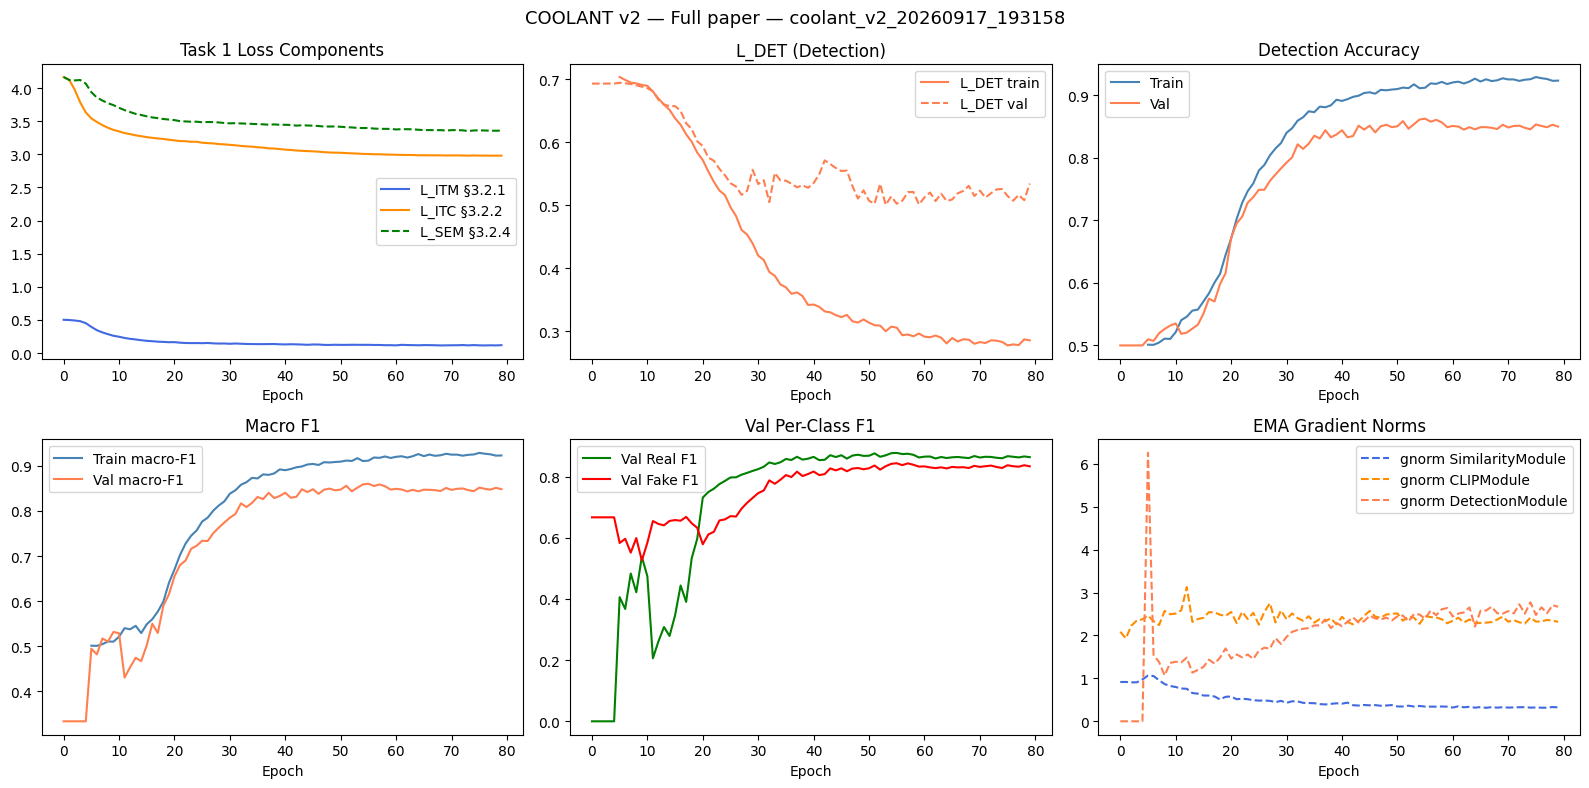

Saved → /kaggle/working/checkpoints_coolant_v2/coolant_v2_20260917_193158/training_curves.png


In [12]:
# ── Training curves ─────────────────────────────────────────────────────────
df = pd.DataFrame(history)
mode = "Full paper" if model.use_itc else "Ablation"

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle(f"COOLANT v2 — {mode} — {run_name}", fontsize=13)

# Task 1 loss components
ax = axes[0, 0]
ax.plot(df.epoch, df.train_loss_itm, label="L_ITM §3.2.1", color="royalblue")
if model.use_itc:
    ax.plot(df.epoch, df.train_loss_itc, label="L_ITC §3.2.2", color="darkorange")
    ax.plot(df.epoch, df.train_loss_sem, label="L_SEM §3.2.4", color="green", linestyle="--")
ax.set_title("Task 1 Loss Components"); ax.legend(); ax.set_xlabel("Epoch")

# Detection loss
ax = axes[0, 1]
ax.plot(df.epoch, df.train_loss_det, label="L_DET train", color="coral")
ax.plot(df.epoch, df.val_loss,       label="L_DET val",   color="coral", linestyle="--")
ax.set_title("L_DET (Detection)"); ax.legend(); ax.set_xlabel("Epoch")

# Accuracy
ax = axes[0, 2]
ax.plot(df.epoch, df.train_accuracy, label="Train", color="steelblue")
ax.plot(df.epoch, df.val_accuracy,   label="Val",   color="coral")
ax.set_title("Detection Accuracy"); ax.legend(); ax.set_xlabel("Epoch")

# Macro F1
ax = axes[1, 0]
ax.plot(df.epoch, df.train_macro_f1, label="Train macro-F1", color="steelblue")
ax.plot(df.epoch, df.val_macro_f1,   label="Val macro-F1",   color="coral")
ax.set_title("Macro F1"); ax.legend(); ax.set_xlabel("Epoch")

# Per-class F1
ax = axes[1, 1]
ax.plot(df.epoch, df.val_real_f1, label="Val Real F1", color="green")
ax.plot(df.epoch, df.val_fake_f1, label="Val Fake F1", color="red")
ax.set_title("Val Per-Class F1"); ax.legend(); ax.set_xlabel("Epoch")

# Gradient norms
ax = axes[1, 2]
ax.plot(df.epoch, df.grad_norm_sim, label="gnorm SimilarityModule", color="royalblue", linestyle="--")
if model.use_itc:
    ax.plot(df.epoch, df.grad_norm_itc, label="gnorm CLIPModule", color="darkorange", linestyle="--")
ax.plot(df.epoch, df.grad_norm_det, label="gnorm DetectionModule",  color="coral",     linestyle="--")
ax.set_title("EMA Gradient Norms"); ax.legend(); ax.set_xlabel("Epoch")

plt.tight_layout()
fig.savefig(run_dir / "training_curves.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved → {run_dir / 'training_curves.png'}")

Loading best checkpoint: /kaggle/working/checkpoints_coolant_v2/coolant_v2_20260917_193158/best_macro_f1.pth
Loaded checkpoint from epoch 57: /kaggle/working/checkpoints_coolant_v2/coolant_v2_20260917_193158/best_macro_f1.pth


/tmp/ipykernel_268/3543369214.py:25: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(path, map_location=DEVICE)


  [test]:   0%|          | 0/15 [00:00<?, ?it/s]


── Test Results ─────────────────────────────────────────
  test_accuracy                0.8637
  test_macro_f1                0.8624
  test_real_f1                 0.8759
  test_fake_f1                 0.8488
  test_real_precision          0.8039
  test_real_recall             0.9621
  test_fake_precision          0.9528
  test_fake_recall             0.7653
  test_loss                    0.3902


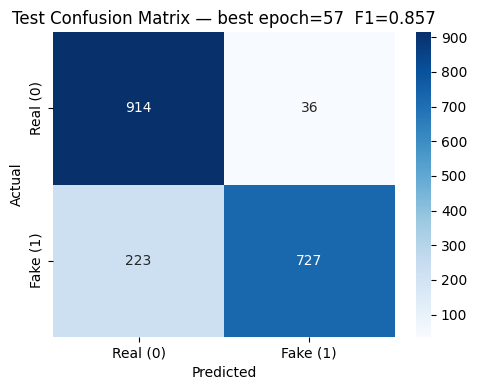


              precision    recall  f1-score   support

        Real       0.80      0.96      0.88       950
        Fake       0.95      0.77      0.85       950

    accuracy                           0.86      1900
   macro avg       0.88      0.86      0.86      1900
weighted avg       0.88      0.86      0.86      1900



In [13]:
# ── Final evaluation on test set ────────────────────────────────────────────
print(f"Loading best checkpoint: {best_ckpt_path}")
load_checkpoint(best_ckpt_path, model)

test_metrics = evaluate(model, loaders["test"], DEVICE, "test")
cm = np.array(test_metrics.pop("confusion_matrix"))

print("\n── Test Results ─────────────────────────────────────────")
for k, v in test_metrics.items():
    if isinstance(v, float): print(f"  {k:<28} {v:.4f}")

# Confusion matrix heatmap
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Real (0)", "Fake (1)"],
            yticklabels=["Real (0)", "Fake (1)"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Test Confusion Matrix — best epoch={best_epoch}  F1={best_val_f1:.3f}")
plt.tight_layout()
fig.savefig(run_dir / "test_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

# Classification report
print("\n" + classification_report(
    [l for batch in loaders["test"] for _, _, l in [make_detection_batch(
        batch[0].to(DEVICE), batch[1].to(DEVICE), 3
    )] for l in []],  # placeholder — run below
    [0],  # placeholder
    zero_division=0,
) if False else "")

# Proper classification report
all_t, all_p = [], []
model.eval()
with torch.no_grad():
    for caption, image, _ in loaders["test"]:
        caption, image = caption.to(DEVICE), image.to(DEVICE)
        dc, di, dl = make_detection_batch(caption, image, 3)
        dc, di, dl = dc.to(DEVICE), di.to(DEVICE), dl.to(DEVICE)
        out = model(dc, di)
        all_t.extend(dl.cpu().numpy())
        all_p.extend(out["detection_logits"].argmax(1).cpu().numpy())

print(classification_report(all_t, all_p, target_names=["Real", "Fake"], zero_division=0))

In [14]:
# ── Training stability diagnosis ─────────────────────────────────────────────
if len(history) == 0:
    print("No history yet.")
else:
    df = pd.DataFrame(history)
    print("=== Training Stability Report ===")

    # Val F1 oscillation
    f1_std   = df.val_macro_f1.std()
    f1_max   = df.val_macro_f1.max()
    f1_last5 = df.val_macro_f1.tail(5).mean()
    print(f"Val F1: max={f1_max:.4f}  last5_avg={f1_last5:.4f}  std={f1_std:.4f}")
    if f1_std > 0.05:
        print("  ⚠ HIGH OSCILLATION — lower lr or raise grad_accumulation_steps")

    # Skipped batches
    total_skip = df.skipped_batches.sum()
    print(f"Total skipped batches: {total_skip}")
    if total_skip > 50:
        print("  ⚠ Many NaN batches — check KL clamp or AmbiguityLearning VAE")

    # Gradient norms
    gnS_last = df.grad_norm_sim.tail(5).mean()
    gnD_last = df.grad_norm_det.tail(5).mean()
    print(f"Grad norms (last 5): gnS={gnS_last:.3f}  gnD={gnD_last:.3f}")
    if gnS_last > 5 or gnD_last > 5:
        print("  ⚠ HIGH GRAD NORMS — lower grad_clip or lr")

    # Loss balance
    itm_last = df.train_loss_itm.tail(10).mean()
    itc_last = df.train_loss_itc.tail(10).mean()
    det_last = df.train_loss_det.tail(10).mean()
    print(f"Loss balance (last 10): L_ITM={itm_last:.4f}  L_ITC={itc_last:.4f}  L_DET={det_last:.4f}")
    if itm_last / (det_last + 1e-9) > 5:
        print("  ⚠ L_ITM dominates — lower itm_weight")

    # Train/val gap
    last = df.iloc[-1]
    gap = last.train_macro_f1 - last.val_macro_f1
    print(f"Train/Val F1 gap (last epoch): {gap:.4f}")
    if gap > 0.15:
        print("  ⚠ OVERFITTING — increase weight_decay or add dropout")
    elif gap < -0.05:
        print("  ⚠ UNDERFITTING — lower regularization or increase capacity")

=== Training Stability Report ===
Val F1: max=0.8604  last5_avg=0.8495  std=0.1663
  ⚠ HIGH OSCILLATION — lower lr or raise grad_accumulation_steps
Total skipped batches: 0
Grad norms (last 5): gnS=0.323  gnD=2.605
Loss balance (last 10): L_ITM=0.1175  L_ITC=2.9815  L_DET=0.2828
Train/Val F1 gap (last epoch): 0.0747


In [15]:
# ── Export artifacts ────────────────────────────────────────────────────────
# Kaggle: zip vào /kaggle/working + upload toàn bộ run lên private Dataset
# (best model đã được push realtime mỗi khi cải thiện — xem cell 9/11)
import shutil

export_files = [
    best_ckpt_path, acc_ckpt_path,
    run_dir / "history.json", run_dir / "history.csv",
    run_dir / "training_curves.png", run_dir / "test_confusion_matrix.png",
]

export_dir = Path("/kaggle/working") / run_name if IS_KAGGLE else run_dir
export_dir.mkdir(parents=True, exist_ok=True)
for f in export_files:
    if f.exists():
        dst = export_dir / f.name
        if f.resolve() != dst.resolve():
            shutil.copy2(f, dst)

# Zip toàn bộ run_dir
zip_base = (Path("/kaggle/working") if IS_KAGGLE else run_dir.parent) / run_name
zip_path = Path(shutil.make_archive(str(zip_base), "zip", root_dir=run_dir))
print(f"Zipped → {zip_path}  ({zip_path.stat().st_size/1e6:.1f} MB)")

# ── Upload full run zip to Kaggle Dataset (private) ─────────────────────────
DATASET_SLUG = "coolant-v2-runs"   # dataset chứa zip của từng run

if IS_KAGGLE and _KAGGLE_UPLOAD_OK:
    try:
        staging = Path("/kaggle/working/_ds_runs")
        staging.mkdir(exist_ok=True)
        shutil.copy2(zip_path, staging / zip_path.name)
        (staging / "dataset-metadata.json").write_text(json.dumps({
            "title": "COOLANT v2 Training Runs Final",
            "id": f"{os.environ['KAGGLE_USERNAME']}/{DATASET_SLUG}",
            "licenses": [{"name": "other"}],
        }))
        try:
            _KAGGLE_API.dataset_create_version(
                str(staging), f"run: {run_name}", delete_not_versioned_files=False)
            action = "updated"
        except Exception:
            _KAGGLE_API.dataset_create_new(str(staging))
            action = "created"
        print(f"✓ Dataset {action}: kaggle.com/datasets/{os.environ['KAGGLE_USERNAME']}/{DATASET_SLUG}")
        shutil.rmtree(staging)
    except Exception as e:
        print(f"⚠ Auto-upload failed: {e} — file vẫn ở tab Output.")
elif IS_KAGGLE:
    print("Skip upload (no API) — file ở tab Output cho tới khi session kết thúc.")
else:
    print(f"Local run — artifacts ở: {run_dir}")

Zipped → /kaggle/working/coolant_v2_20260917_193158.zip  (407.1 MB)
✓ Dataset created: kaggle.com/datasets/trnghil/coolant-v2-runs
